# 4 · Training, step by step

Everything `train/train.py` printed or saved while the networks learned, turned into tables and pictures:

* **4.1–4.2** the setup each run printed and the epoch-by-epoch log of one run as a table,
* **4.3–4.4** loss, mIoU, accuracy and learning rate over the epochs, for one run and for all 11 runs,
* **4.5** test results of all runs as heatmaps (per class, per world region, per settlement type),
* **4.6** **watching the model learn**: a run that saved its predictions for 6 fixed validation scenes after
  every epoch (from the untrained network, epoch 0, to the end), the loss after every batch, and per-class IoU
  per epoch: how the output maps change while the network trains.

Sources: `train/runs_<run>.log` (printed text), `train/runs/<run>/history.csv` (one row per epoch),
`steps.csv` (one row per batch) and `snapshots/` (predictions per epoch).

### Why this notebook

The scores in notebook 02 are the end result. This notebook shows **the process**: how fast the networks learn, when
they start to overfit, which classes come first, and how a predicted map develops from random to final. It also
connects every number printed during training to a chart, so the text logs and the pictures can be read side by
side.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent                  # the s1-lulc folder
sys.path[:0] = [str(ROOT / "data"), str(ROOT / "train"), str(ROOT / "prototype")]
DATA, PREP, RUNS = ROOT / "data" / "tiles_v0", ROOT / "data" / "tiles_v0" / "prepared", ROOT / "train" / "runs"
from classes import CLASS_NAMES, DISPLAY_NAMES, CLASS_COLOURS, N_CLASSES, BUILT
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("project folder:", ROOT)

project folder: /home/jovyan/vault/s1-lulc


In [2]:
import re, io, base64
from IPython.display import HTML
from pipeline import colourise
ORDER = ["E1", "E1s1", "E0", "E1y", "E2a", "E2b", "E3", "E3s1", "E3v", "E5", "E6", "E1half"]
runs = [r for r in ORDER if (RUNS / r / "history.csv").exists()]
runs += sorted(d.name for d in RUNS.iterdir() if (d / "history.csv").exists() and d.name not in runs)
hist = {r: pd.read_csv(RUNS / r / "history.csv") for r in runs}
WATCH = next((r for r in ["E3v"] + runs if (RUNS / r / "snapshots" / "examples.npz").exists()), None)
print("runs with a training history:", ", ".join(runs))
print("run with prediction snapshots (section 4.6):", WATCH or "none yet")
def log_text(r):
    f = ROOT / "train" / f"runs_{r}.log"
    return f.read_text(errors="ignore") if f.exists() else ""

runs with a training history: E1, E1s1, E0, E1y, E2a, E2b, E3, E3s1, E3v, E5, E6, E1half
run with prediction snapshots (section 4.6): E3v


## 4.1 What each run printed before training

At the start, `train.py` prints the number of training and validation scenes, how strongly the balanced sampler
reweights them (*effective sample size*: how many independent scenes the weighted draw is worth), the network size,
and the class weights of the loss. The table collects these lines from the log files; the chart shows how the
balanced sampler changes the class mix the network sees.

,label,encoder,upsampling,train scenes,val scenes,effective sample size,parameters (M),trainable (M),epochs run,best epoch,best val mIoU,early stopped,time (min),s / epoch
run,,,,,,,,,,,,,,
E1,hyb_s,imagenet,interp,19852,2792,12785,24.4,24.4,34,24,0.542,yes,25.901,45.708
E1s1,hyb_s,imagenet,interp,19852,2792,12785,24.4,24.4,25,15,0.552,yes,18.552,44.525
E0,dw,imagenet,interp,19852,2792,12781,24.4,24.4,24,14,0.536,yes,17.923,44.808
E1y,hyb_y,imagenet,interp,23887,3294,16715,24.4,24.4,25,15,0.519,yes,22.056,52.934
E2a,hyb_s,frozen,interp,19852,2792,12785,24.4,3.2,21,11,0.519,yes,14.307,40.878
E2b,hyb_s,none,interp,19852,2792,12785,24.4,24.4,24,14,0.546,yes,17.959,44.896
E3,hyb_s,imagenet,transposed,19852,2792,12785,25.8,25.8,27,17,0.555,yes,19.921,44.270
E3s1,hyb_s,imagenet,transposed,19852,2792,12785,25.8,25.8,19,9,0.553,yes,14.217,44.896
E3v,hyb_s,imagenet,transposed,19852,2792,12785,25.8,25.8,34,24,0.562,yes,25.457,44.924


**Class weights of the loss** (printed as `Class weights: ...`; larger = rarer class in what the sampler draws)

,water,trees,grass_shrub,crops,built,bare_snow
E1,1.40,0.84,0.96,0.96,0.75,1.08
E1s1,1.40,0.84,0.96,0.96,0.75,1.08
E0,1.40,0.85,0.95,0.97,0.75,1.07
E1y,1.39,0.83,0.94,0.92,0.73,1.19
E2a,1.40,0.84,0.96,0.96,0.75,1.08
E2b,1.40,0.84,0.96,0.96,0.75,1.08
E3,1.40,0.84,0.96,0.96,0.75,1.08
E3s1,1.40,0.84,0.96,0.96,0.75,1.08
E3v,1.40,0.84,0.96,0.96,0.75,1.08
E5,1.40,0.84,0.96,0.96,0.75,1.08


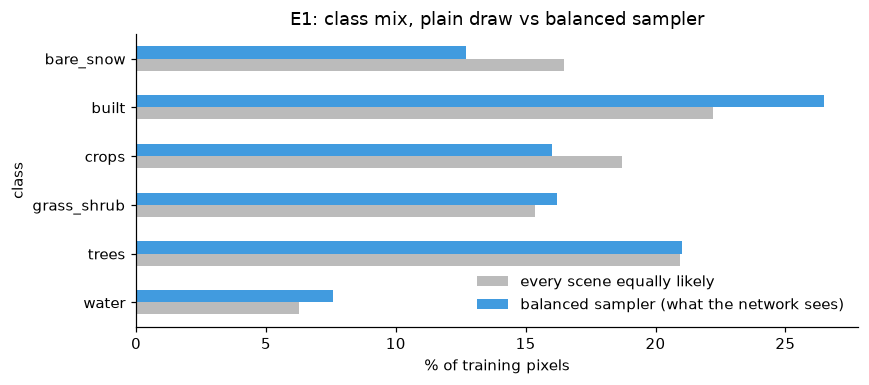

In [3]:
def grab(pat, t, f=float):
    m = re.search(pat, t)
    return f(m[1]) if m else np.nan
rows = []
for r in runs:
    t, h = log_text(r), hist[r]
    cfg = json.loads((RUNS / r / "config.json").read_text()) if (RUNS / r / "config.json").exists() else {}
    best = h.val_miou.idxmax()
    rows.append({"run": r, "label": cfg.get("label"), "encoder": "frozen" if cfg.get("freeze_encoder") else cfg.get("encoder_weights"),
                 "upsampling": cfg.get("upsample"), "train scenes": grab(r"train (\d+), val", t, int),
                 "val scenes": grab(r"val (\d+);", t, int), "effective sample size": grab(r"effective sample size (\d+)", t, int),
                 "parameters (M)": grab(r"([\d.]+)M parameters", t), "trainable (M)": grab(r"\(([\d.]+)M trainable\)", t),
                 "epochs run": len(h), "best epoch": int(h.epoch[best]), "best val mIoU": h.val_miou[best],
                 "early stopped": "yes" if "Early stopping" in t else ("no" if t else "?"),
                 "time (min)": h.seconds.sum() / 60, "s / epoch": h.seconds.mean()})
setup = pd.DataFrame(rows).set_index("run")
display(setup.round(3))
w = {}
for r in runs:
    m = re.search(r"Class weights: (.*)", log_text(r))
    if m:
        w[r] = {k: float(v) for k, v in (x.rsplit(" ", 1) for x in m[1].split(", "))}
if w:
    display(Markdown("**Class weights of the loss** (printed as `Class weights: ...`; larger = rarer class in what the sampler draws)"))
    display(pd.DataFrame(w).T.round(2))
r0 = "E1" if "E1" in runs else runs[0]
f = RUNS / r0 / "train_class_shares.csv"
if f.exists():
    cs = pd.read_csv(f).set_index("class")
    ax = cs.plot.barh(figsize=(8, 3.6), color=["#bbbbbb", "#419bdf"])
    ax.set_xlabel("% of training pixels"); ax.set_title(f"{r0}: class mix, plain draw vs balanced sampler")
    ax.legend(["every scene equally likely", "balanced sampler (what the network sees)"], frameon=False)
    plt.tight_layout(); plt.show()

**Reading the table.** One row per run. *train / val scenes*: samples available; *effective sample size*: with
weighted drawing, some scenes are drawn often and some rarely; this is the number of equally weighted scenes the
draw is worth (higher = more variety); *parameters*: 24.4 M for the U-Net (*trainable* is less for E2a, frozen
encoder); *epochs run*, *best epoch*, *best val mIoU*, *early stopped*; *time*. The class weights show how much
each class counts in the loss; the bar chart compares the class mix of plain drawing with what the balanced sampler
delivers.

## 4.2 The epoch log as a table

During training every epoch printed one line such as
`ep  12  loss 0.981/1.204  mIoU 0.612/0.531  OA 0.790/0.683  51s  *best`.
Here are those lines of one run (the prototype's main model, E3) as a table. Colours: greener = better val mIoU,
bars = loss; ★ marks a new best validation mIoU, the checkpoint kept for testing.

In [4]:
RUN = "E3" if "E3" in runs else runs[0]
h = hist[RUN]
t = log_text(RUN)
lines = [l for l in t.splitlines() if l.startswith("ep ")]
if lines:
    print(f"As printed ({RUN}, first and last 3 epochs):")
    print("\n".join(lines[:3] + ["   ..."] + lines[-3:]), "\n")
cols = [c for c in ["epoch", "train_loss", "val_loss", "train_miou", "val_miou", "train_oa", "val_oa", "lr", "seconds"] if c in h]
tab = h[cols].copy()
tab["new best"] = np.where(h.val_miou >= h.val_miou.cummax(), "★", "")
try:
    sty = (tab.style.hide(axis="index")
           .format({c: "{:.3f}" for c in cols if c not in ("epoch", "lr", "seconds")} | {"lr": "{:.1e}", "seconds": "{:.0f}"})
           .background_gradient(subset=["val_miou"], cmap="Greens")
           .bar(subset=["train_loss", "val_loss"], color="#f4a582"))
    display(sty)
except Exception:          # pandas Styler needs jinja2
    display(tab.round(3))

As printed (E3, first and last 3 epochs):
ep   1  loss 1.916/1.742  mIoU 0.364/0.423  val OA 0.615  44s  *best
ep   2  loss 1.562/1.580  mIoU 0.446/0.479  val OA 0.667  46s  *best
ep   3  loss 1.488/1.556  mIoU 0.470/0.489  val OA 0.683  45s  *best
   ...
ep  25  loss 0.911/1.560  mIoU 0.652/0.527  val OA 0.696  44s
ep  26  loss 0.888/1.526  mIoU 0.660/0.528  val OA 0.700  42s
ep  27  loss 0.886/1.489  mIoU 0.661/0.543  val OA 0.713  43s 



epoch,train_loss,val_loss,train_miou,val_miou,val_oa,lr,seconds,new best
1,1.916,1.742,0.364,0.423,0.615,1.0e-03,44,★
2,1.562,1.580,0.446,0.479,0.667,1.0e-03,46,★
3,1.488,1.556,0.470,0.489,0.683,9.9e-04,45,★
4,1.413,1.645,0.494,0.465,0.658,9.9e-04,44,
5,1.377,1.619,0.507,0.460,0.649,9.7e-04,44,
6,1.343,1.494,0.516,0.516,0.691,9.6e-04,44,★
7,1.293,1.444,0.533,0.545,0.715,9.4e-04,44,★
8,1.266,1.452,0.542,0.535,0.708,9.2e-04,43,
9,1.245,1.480,0.548,0.524,0.688,9.0e-04,44,
10,1.210,1.520,0.560,0.515,0.681,8.7e-04,44,


**Reading the epoch table.** One row = one printed `ep` line. train / val loss: lower is better; train / val mIoU
and OA: higher is better; lr: learning rate in that epoch; seconds per epoch. The ★ marks epochs where validation
mIoU reached a new best: those weights were saved as `best.pt`. After the last ★, 10 more epochs ran without
improvement, then early stopping ended the run.

## 4.3 One run: loss, mIoU, accuracy and learning rate per epoch

* **Loss** (cross-entropy + Dice) should fall for both train and validation; when validation stops falling while
  training keeps falling, the network starts memorising the training places.
* **mIoU**: the shaded gap between train and validation is the generalisation gap.
* **Accuracy** (OA): share of correctly classified pixels.
* **Learning rate**: one warm-up epoch, then a cosine decay (`train.py`), which is why the curves calm down at the end.
* Dotted line = best epoch (checkpoint kept); the grey band = the 10 epochs of patience before early stopping.

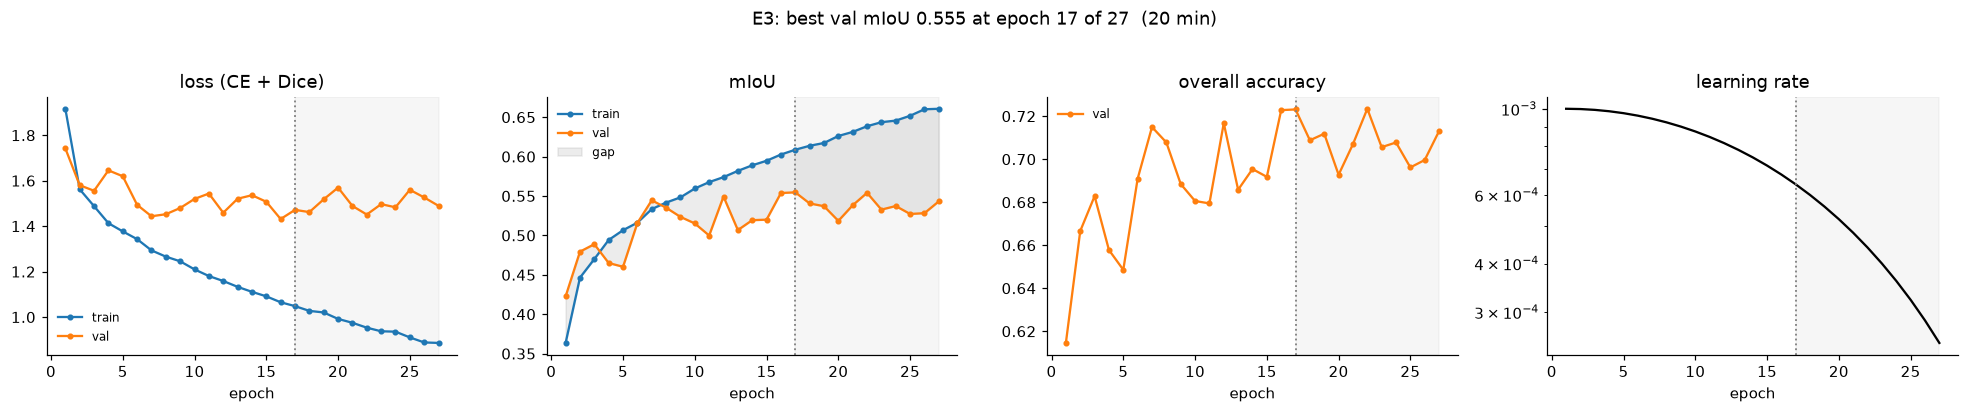

In [5]:
def dashboard(r):
    h = hist[r]; best = int(h.epoch[h.val_miou.idxmax()])
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
    ax[0].plot(h.epoch, h.train_loss, "o-", ms=3, label="train"); ax[0].plot(h.epoch, h.val_loss, "o-", ms=3, label="val")
    ax[0].set_title("loss (CE + Dice)")
    ax[1].plot(h.epoch, h.train_miou, "o-", ms=3, label="train"); ax[1].plot(h.epoch, h.val_miou, "o-", ms=3, label="val")
    ax[1].fill_between(h.epoch, h.val_miou, h.train_miou, color="grey", alpha=0.15, label="gap")
    ax[1].set_title("mIoU")
    if "train_oa" in h: ax[2].plot(h.epoch, h.train_oa, "o-", ms=3, label="train")
    ax[2].plot(h.epoch, h.val_oa, "o-", ms=3, label="val", color="C1"); ax[2].set_title("overall accuracy")
    ax[3].plot(h.epoch, h.lr, color="k"); ax[3].set_yscale("log"); ax[3].set_title("learning rate")
    for a in ax:
        a.axvline(best, color="grey", ls=":", lw=1.2); a.set_xlabel("epoch")
        if len(h) > best: a.axvspan(best, h.epoch.max(), color="grey", alpha=0.07)
    for a in ax[:3]: a.legend(frameon=False, fontsize=8)
    fig.suptitle(f"{r}: best val mIoU {h.val_miou.max():.3f} at epoch {best} of {len(h)}  "
                 f"({h.seconds.sum() / 60:.0f} min)", y=1.03)
    plt.tight_layout(); plt.show()
dashboard(RUN)

Every other run the same way (scroll):

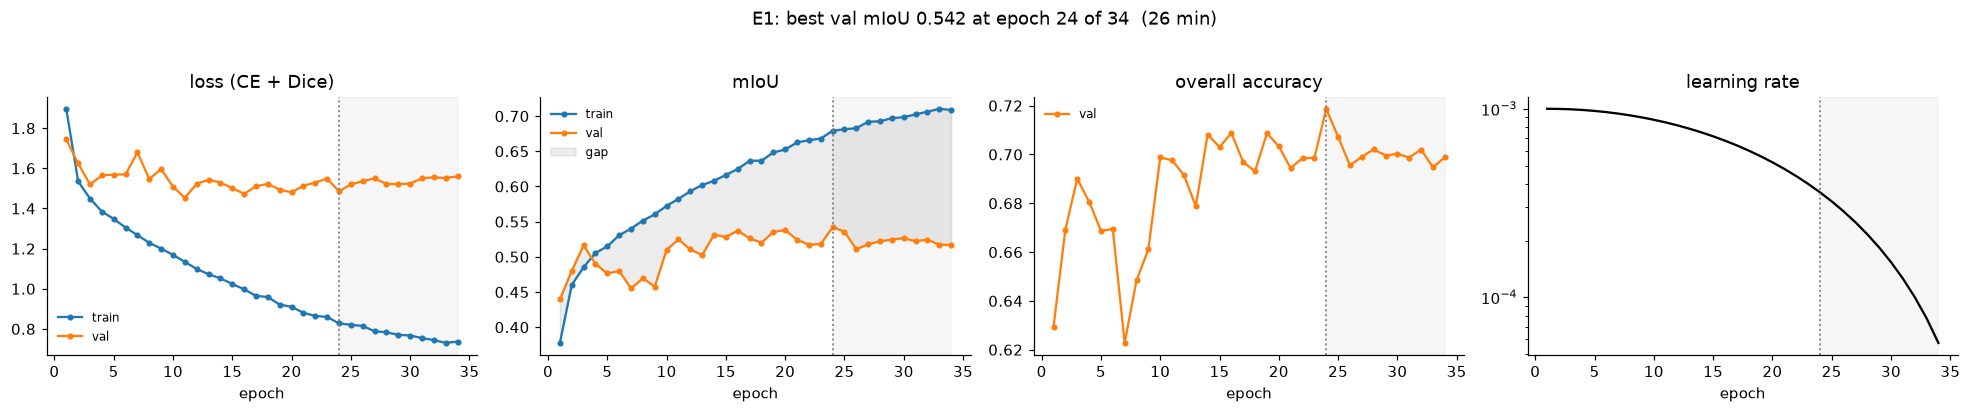

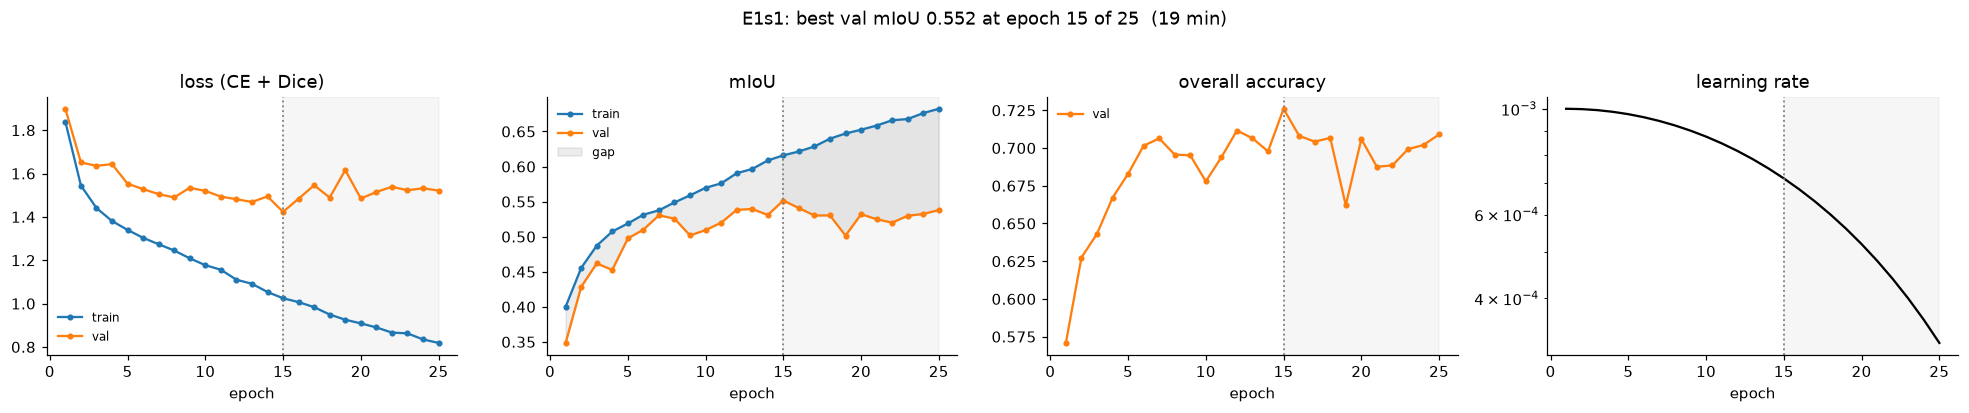

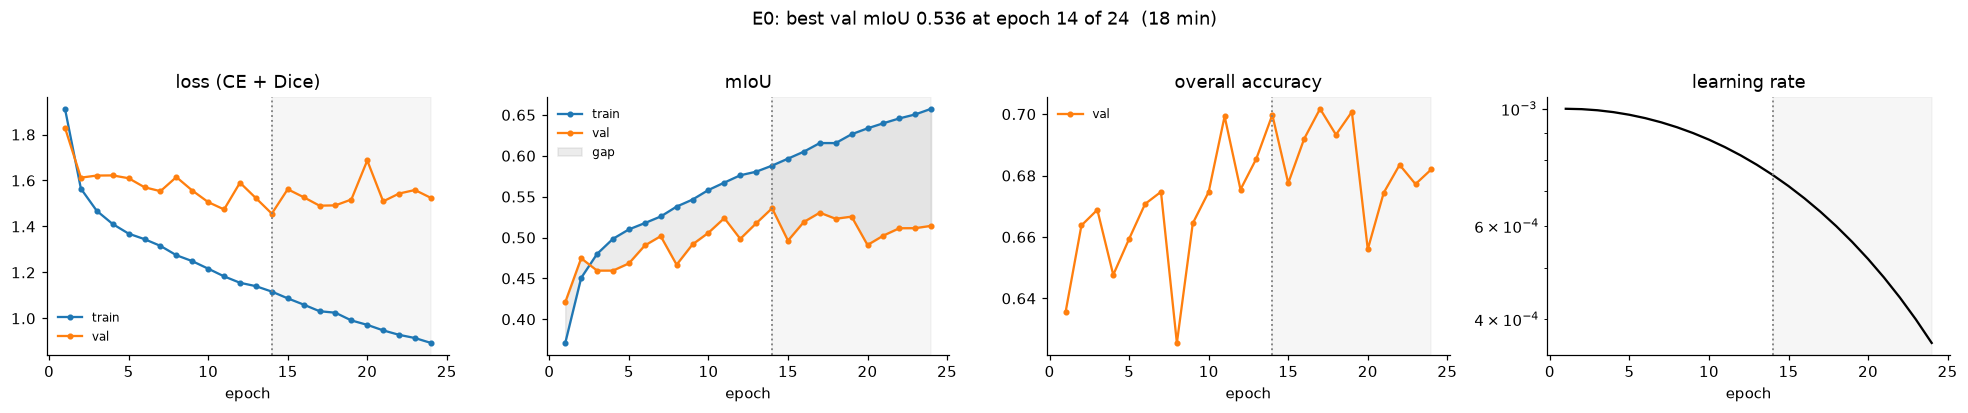

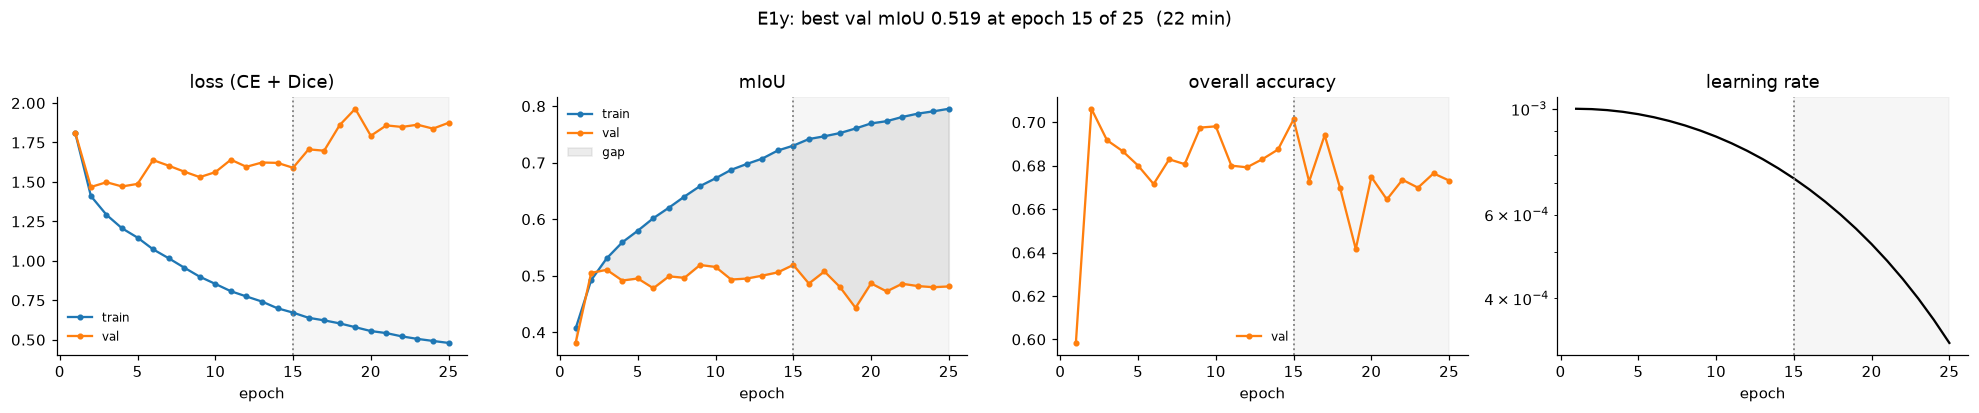

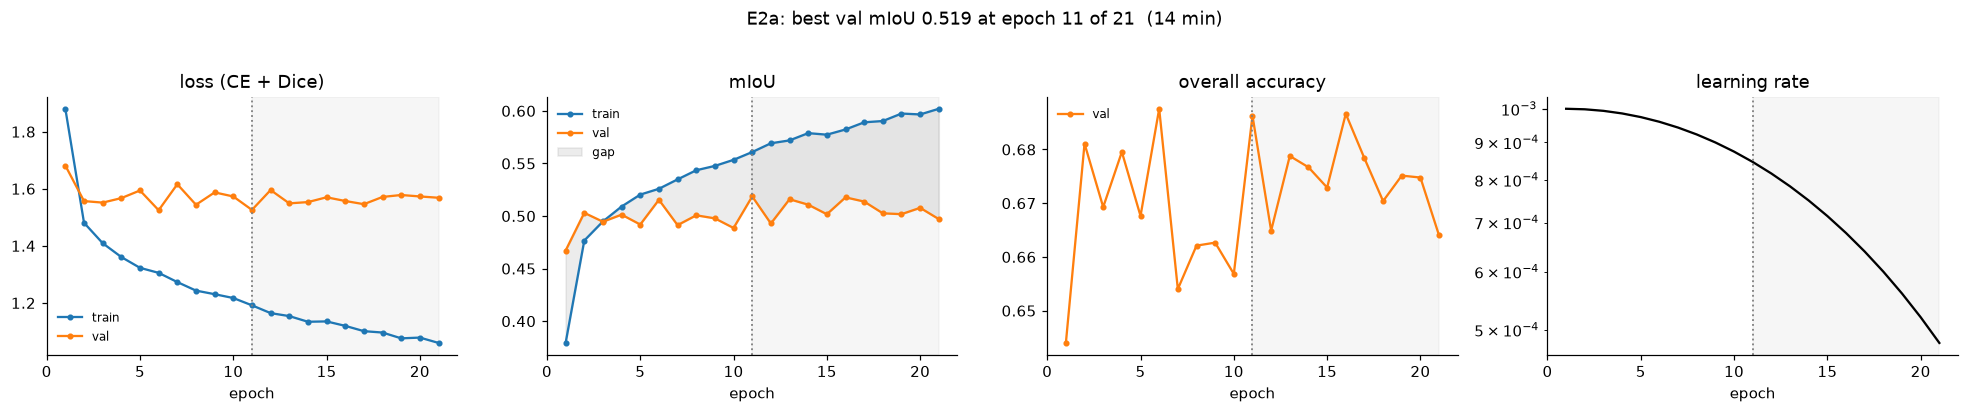

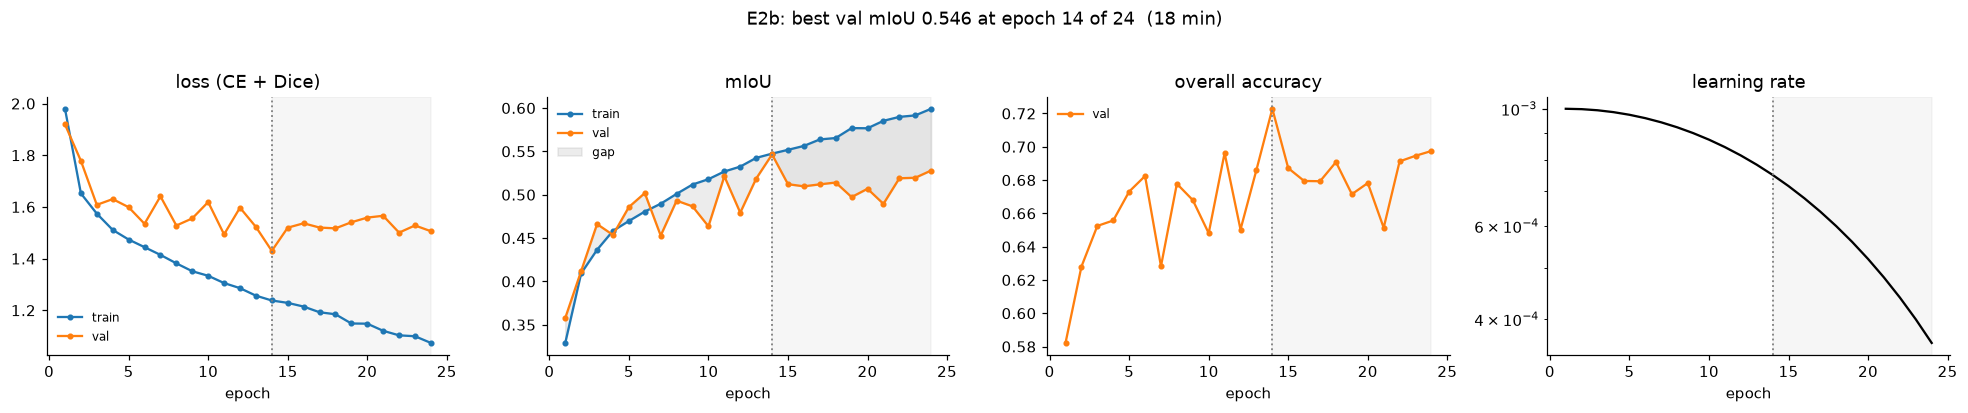

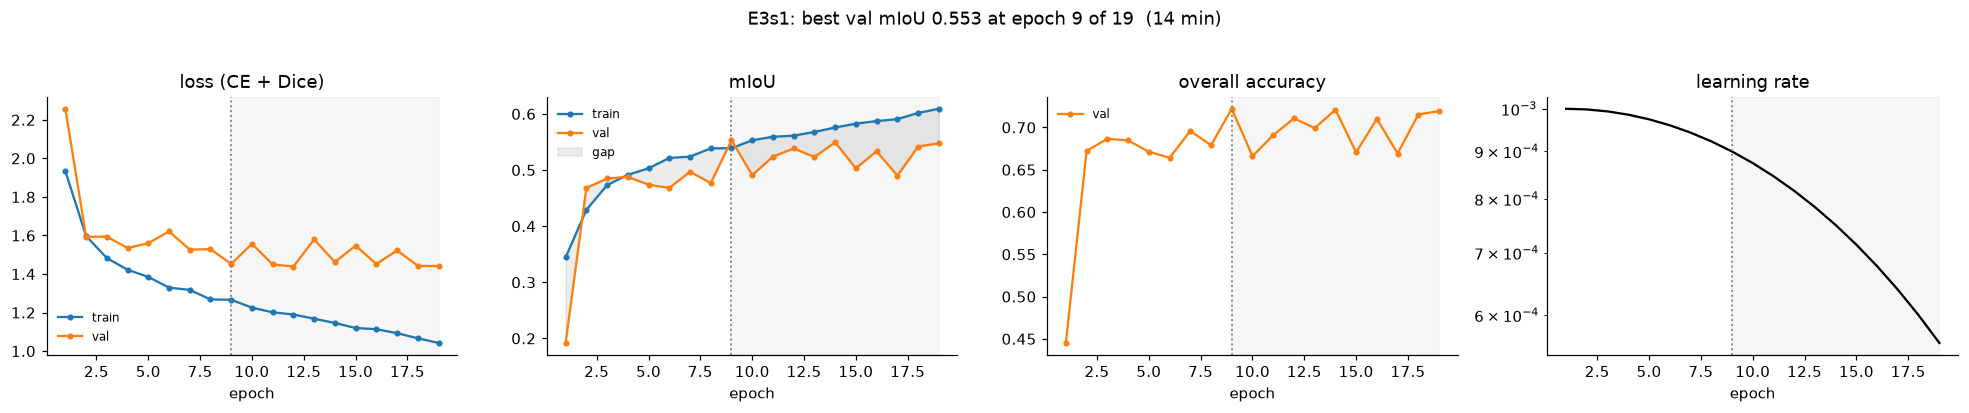

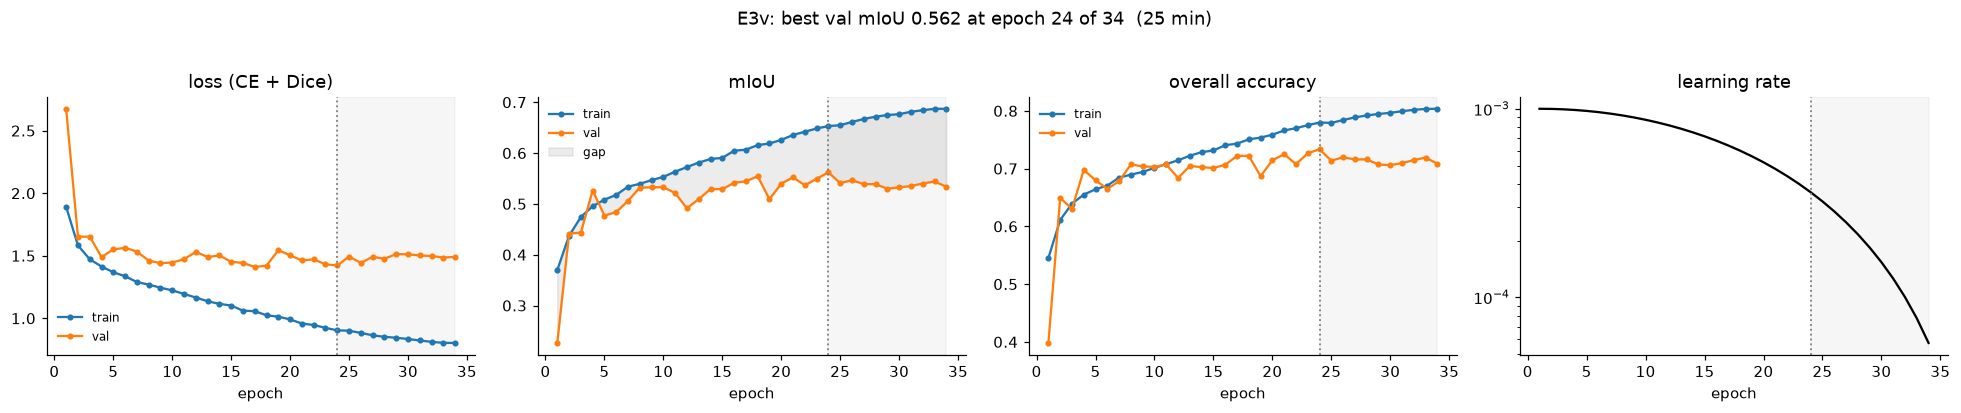

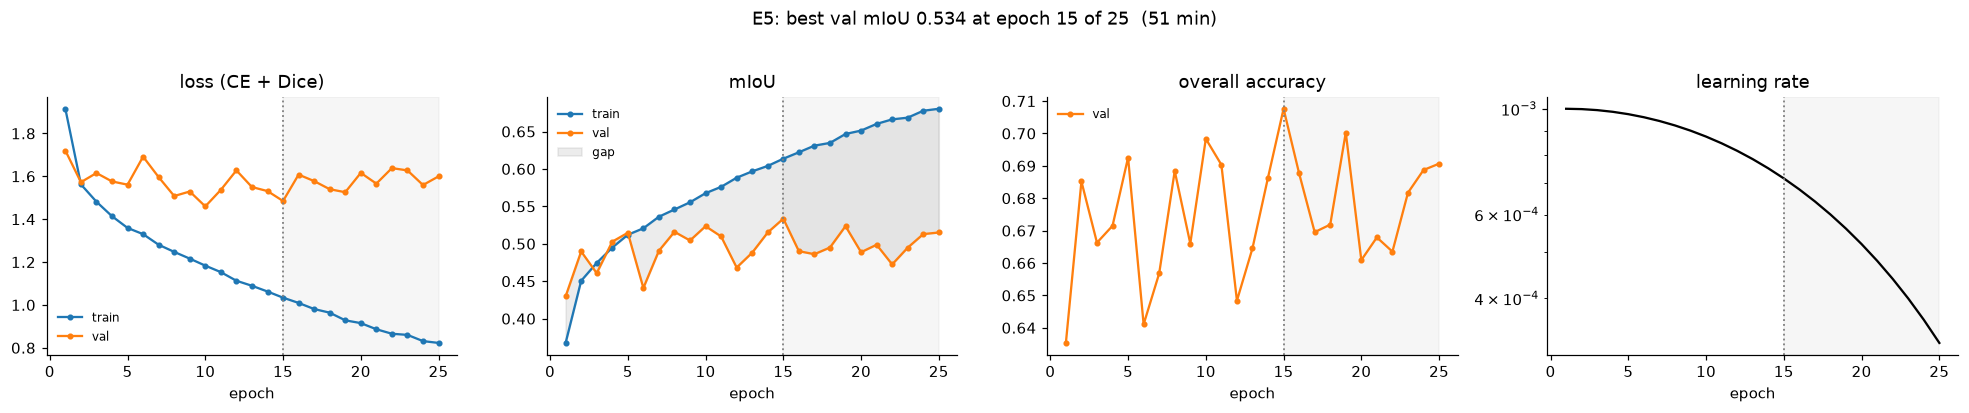

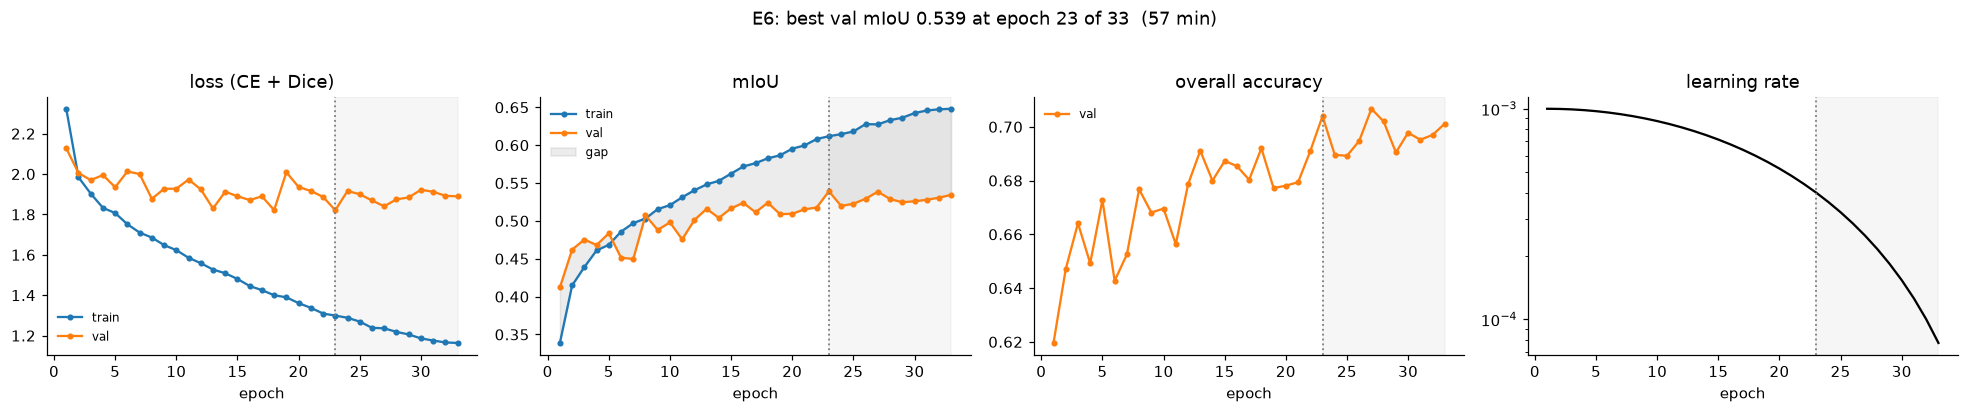

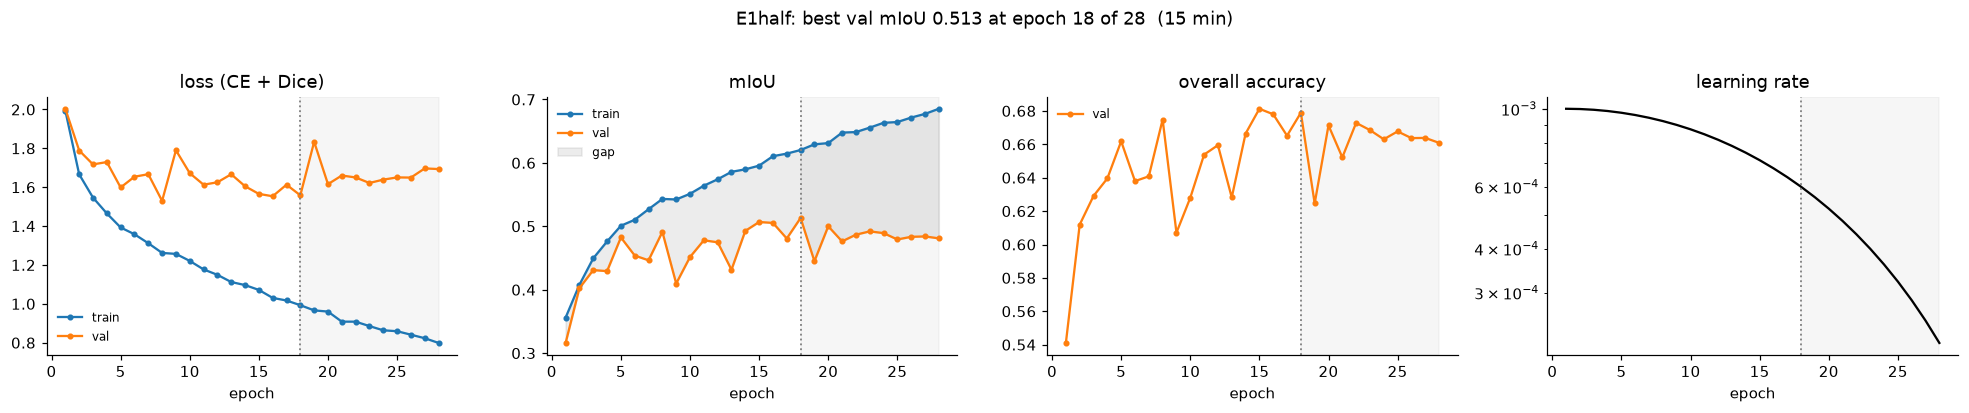

In [6]:
for r in runs:
    if r != RUN:
        dashboard(r)

## 4.4 All runs on one chart

The same curves overlaid: how fast each variant learns and where it levels off. Frozen encoder (E2a) and no
pretraining (E2b) start lower; E1half has half the training places.

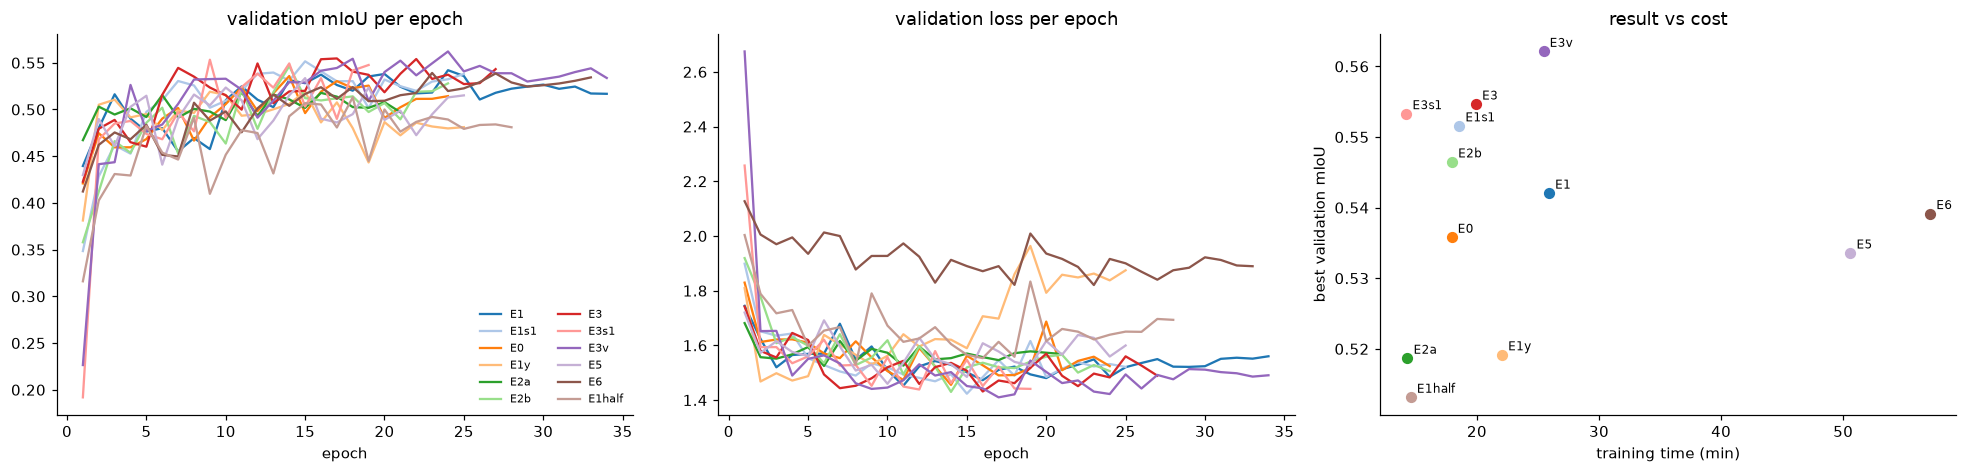

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
cmap = plt.get_cmap("tab20")
for i, r in enumerate(runs):
    h = hist[r]; c = cmap(i % 20)
    ax[0].plot(h.epoch, h.val_miou, color=c, label=r); ax[1].plot(h.epoch, h.val_loss, color=c, label=r)
    ax[2].scatter(h.seconds.sum() / 60, h.val_miou.max(), color=c, s=40)
    ax[2].annotate(r, (h.seconds.sum() / 60, h.val_miou.max()), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax[0].set_title("validation mIoU per epoch"); ax[1].set_title("validation loss per epoch")
for a in ax[:2]: a.set_xlabel("epoch")
ax[0].legend(ncol=2, fontsize=7, frameon=False)
ax[2].set_xlabel("training time (min)"); ax[2].set_ylabel("best validation mIoU"); ax[2].set_title("result vs cost")
plt.tight_layout(); plt.show()

## 4.5 Test results of all runs as heatmaps

From `test_metrics.json` (130 unseen places, one scene per month, each run against its own label). Rows = runs,
columns = classes / world regions / settlement types; greener = better. Notebook 02 has the fair comparison
on the same labels.

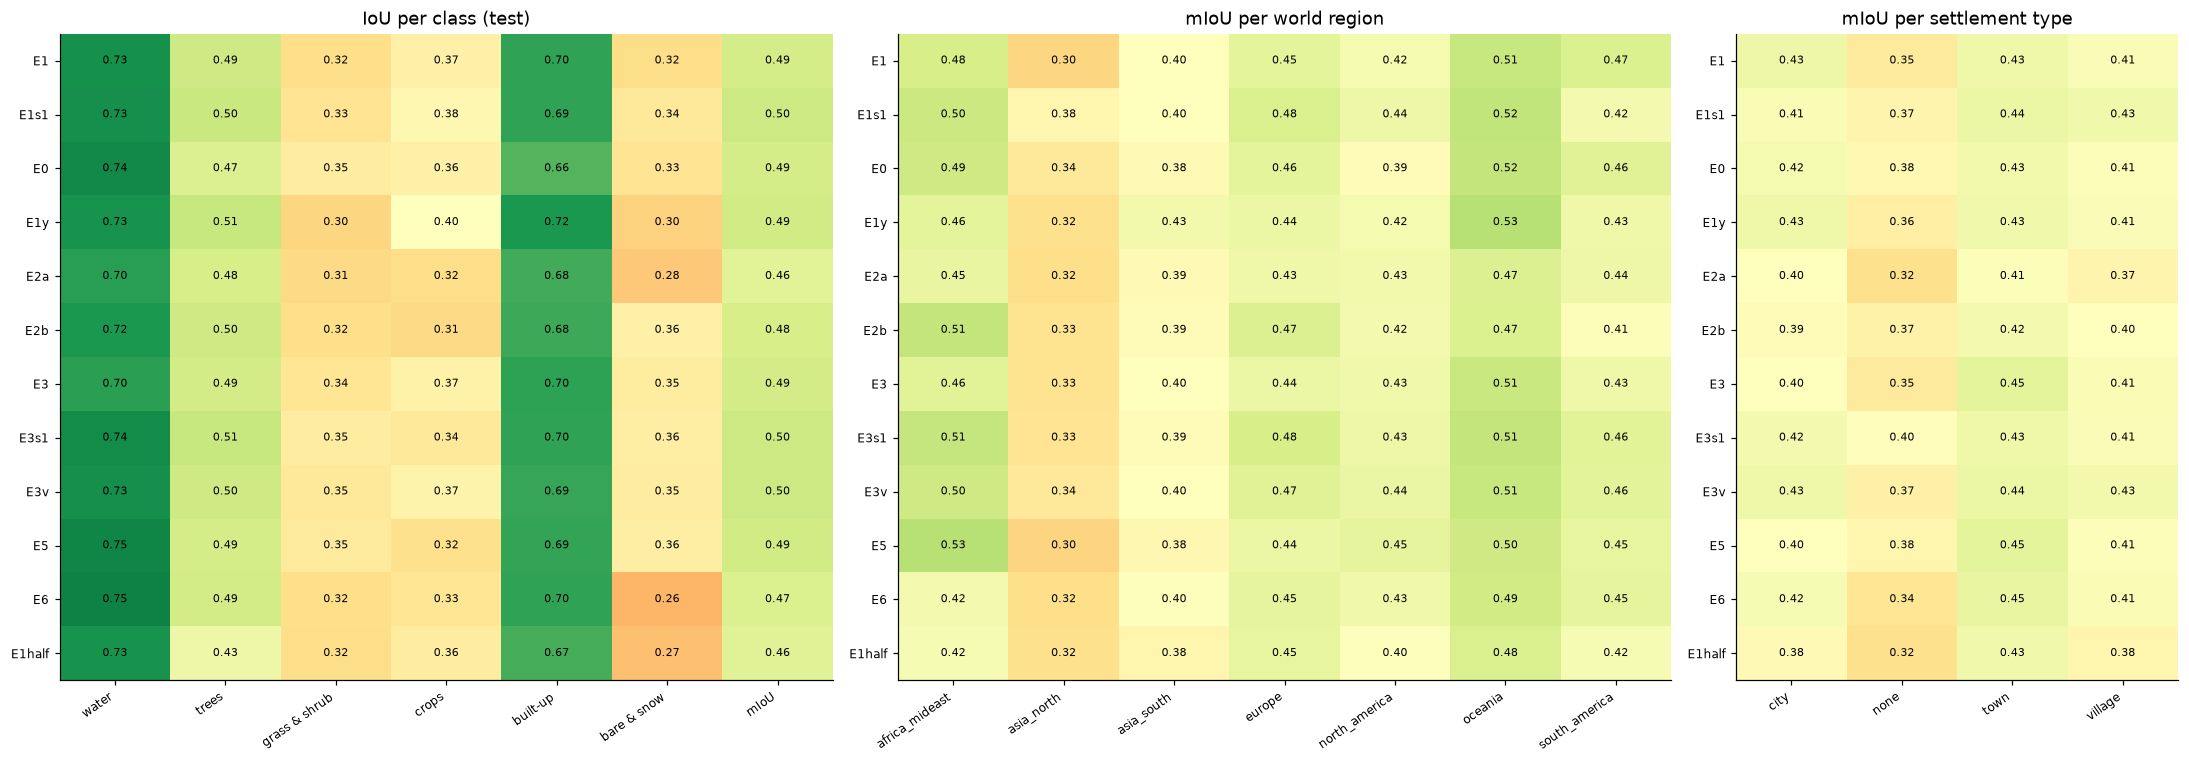

In [8]:
def heat(df, title, ax, vmin=0, vmax=0.8):
    im = ax.imshow(df.to_numpy(float), cmap="RdYlGn", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(df.shape[0]), df.index, fontsize=8)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.iat[i, j]
            if v == v: ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(title)
tm = {r: json.loads((RUNS / r / "test_metrics.json").read_text()) for r in runs if (RUNS / r / "test_metrics.json").exists()}
if tm:
    cls = pd.DataFrame({r: m["per_class_iou"] for r, m in tm.items()}).T; cls.columns = DISPLAY_NAMES
    cls["mIoU"] = [m["overall"]["mIoU"] for m in tm.values()]
    reg = pd.DataFrame({r: {k: v["mIoU"] for k, v in m["per_region"].items()} for r, m in tm.items()}).T
    st_ = pd.DataFrame({r: {k: v["mIoU"] for k, v in m["per_settlement"].items()} for r, m in tm.items()}).T
    fig, ax = plt.subplots(1, 3, figsize=(20, 0.42 * len(tm) + 2), gridspec_kw={"width_ratios": [7, len(reg.columns), 4]})
    heat(cls, "IoU per class (test)", ax[0]); heat(reg, "mIoU per world region", ax[1]); heat(st_, "mIoU per settlement type", ax[2])
    plt.tight_layout(); plt.show()

**Reading the heatmaps.** Look along a column to compare runs (which variant is best for built-up?) and along a row
to see a run's strengths and weaknesses. Regions with few test places (a few in Oceania, for example) vary more
between runs: a difference of 0.05 there can be chance.

## 4.6 Watching the model learn

The run below (`E3v`: the E3 setting with another seed) saved, after every epoch, the predicted map, the confidence
and the built-up probability for 6 fixed validation scenes (`snapshots/`), and the training loss of every batch
(`steps.csv`). Epoch 0 is the network before any training: its decoder is random, so its maps are meaningless (often one class
everywhere).

In [9]:
if WATCH is None:
    print("No run with snapshots yet. On the server:  bash train/run_viz.sh   (about 40 min), then rerun this notebook.")
else:
    W = RUNS / WATCH; hw = hist[WATCH]
    ex = np.load(W / "snapshots" / "examples.npz")
    eps = sorted(int(f.stem[2:]) for f in (W / "snapshots").glob("ep*.npz"))
    snap = {e: np.load(W / "snapshots" / f"ep{e:03d}.npz") for e in eps}
    lab = ex["label"].astype(int); okl = lab >= 0
    acc = pd.Series({e: (snap[e]["pred"][okl] == lab[okl]).mean() for e in eps})
    best_ep = int(hw.epoch[hw.val_miou.idxmax()])
    print(f"{WATCH}: {len(eps) - 1} epochs, snapshots of {len(lab)} validation scenes:")
    display(pd.DataFrame({"place": [f"{s}, {r}" for s, r in zip(ex["settlement"], ex["region"])],
                          "tile": ex["tile_id"], "month of the label": ex["month"] + 1}))

E3v: 34 epochs, snapshots of 6 validation scenes:


,place,tile,month of the label
0,"city, asia_north",t00260,3
1,"town, europe",t00442,9
2,"village, south_america",t00349,11
3,"none, africa_mideast",t00487,5
4,"city, africa_mideast",t00262,2
5,"town, asia_south",t00210,1


**How the snapshots are made.** At the start of training, `train.py` picks 6 validation scenes (one per settlement
type, different regions, each with several classes) and saves their input and label (`snapshots/examples.npz`).
After every epoch it predicts these 6 scenes with the current weights and saves the map, the confidence and the
built-up probability (`snapshots/ep001.npz`, ...). Validation scenes are never trained on, so the snapshots show
how the network does on unseen data.

### Loss after every batch

Each grey point is the loss of one batch of 32 scenes; the line is a moving average over 200 batches. Batches differ
(a city scene is harder than a desert), so single values jump; the trend is what matters. Red = learning rate.

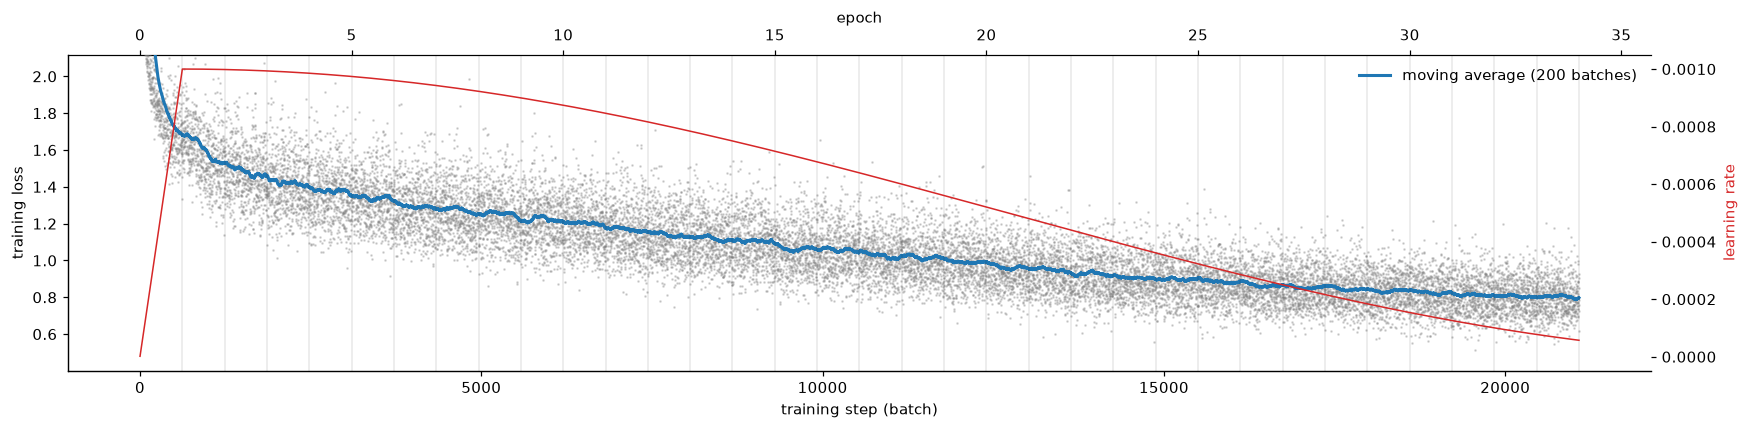

21080 batches; loss first 100 batches 2.40 -> last 100 0.80


In [10]:
if WATCH and (W / "steps.csv").exists():
    stp = pd.read_csv(W / "steps.csv")
    fig, ax = plt.subplots(figsize=(16, 4))
    ax.plot(stp.step, stp.loss, ".", color="grey", ms=1.5, alpha=0.3)
    ax.plot(stp.step, stp.loss.rolling(200, min_periods=20).mean(), color="C0", lw=2, label="moving average (200 batches)")
    for e, g in stp.groupby("epoch"):
        ax.axvline(g.step.max(), color="k", lw=0.3, alpha=0.3)
    ax.set_xlabel("training step (batch)"); ax.set_ylabel("training loss"); ax.set_ylim(top=stp.loss.quantile(0.995))
    ax2 = ax.twinx(); ax2.plot(stp.step, stp.lr, color="C3", lw=1); ax2.set_ylabel("learning rate", color="C3")
    sec = ax.secondary_xaxis("top", functions=(lambda s: s / stp.groupby("epoch").step.max().iloc[0],
                                               lambda e: e * stp.groupby("epoch").step.max().iloc[0]))
    sec.set_xlabel("epoch"); ax.legend(loc="upper right", frameon=False)
    plt.tight_layout(); plt.show()
    print(f"{len(stp)} batches; loss first 100 batches {stp.loss[:100].mean():.2f} -> last 100 {stp.loss[-100:].mean():.2f}")

### Which classes are learned first

Validation IoU of every class after every epoch. Classes with a clear radar signature (water, built-up) are learned
in the first epochs; classes that look alike to radar (grass & shrub vs crops vs bare) need longer and stay lower.

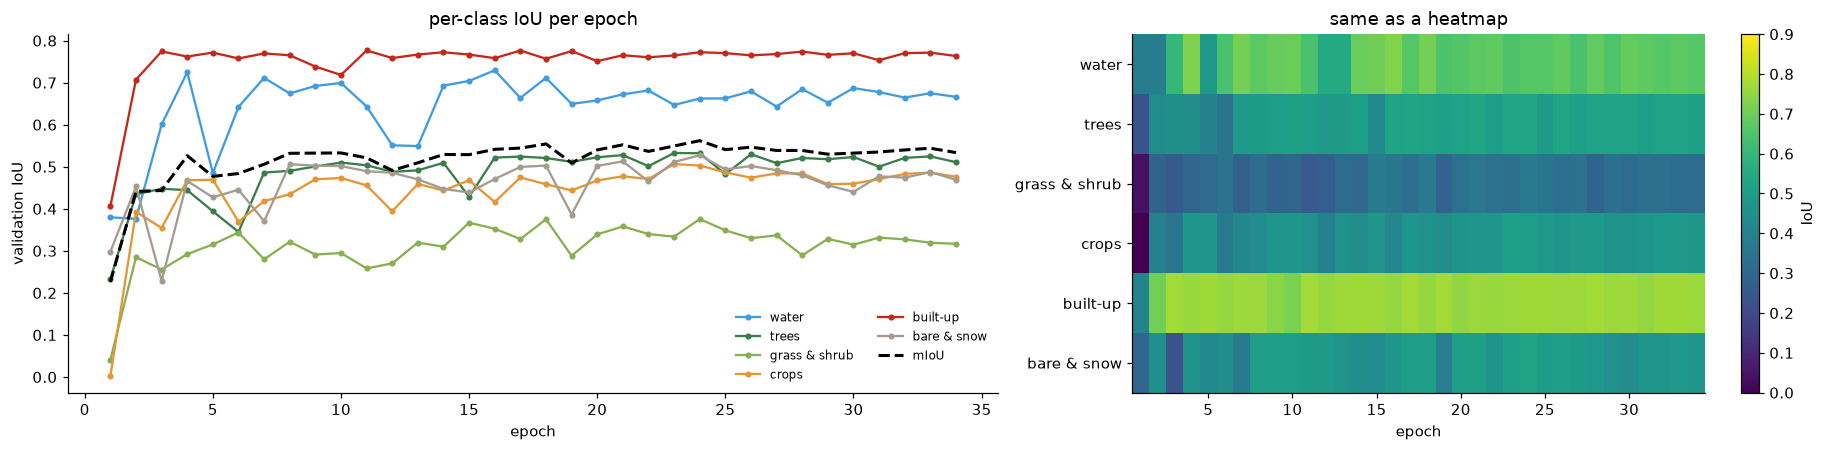

In [11]:
if WATCH:
    ic = [c for c in hw.columns if c.startswith("val_iou_")]
    if ic:
        fig, ax = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
        for k, c in enumerate(ic):
            ax[0].plot(hw.epoch, hw[c], "o-", ms=3, color=CLASS_COLOURS[k], label=DISPLAY_NAMES[k])
        ax[0].plot(hw.epoch, hw.val_miou, "k--", lw=2, label="mIoU"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation IoU")
        ax[0].legend(ncol=2, fontsize=8, frameon=False); ax[0].set_title("per-class IoU per epoch")
        im = ax[1].imshow(hw[ic].to_numpy().T, aspect="auto", cmap="viridis", vmin=0, vmax=0.9,
                          extent=(hw.epoch.min() - .5, hw.epoch.max() + .5, len(ic) - .5, -.5))
        ax[1].set_yticks(range(len(ic)), DISPLAY_NAMES); ax[1].set_xlabel("epoch"); ax[1].set_title("same as a heatmap")
        plt.colorbar(im, ax=ax[1], label="IoU"); plt.tight_layout(); plt.show()

### How the predicted maps change during training

Rows = the 6 fixed validation scenes, columns = the radar input, the label, and the network's prediction after
selected epochs. The number above each map is its pixel accuracy against the label.

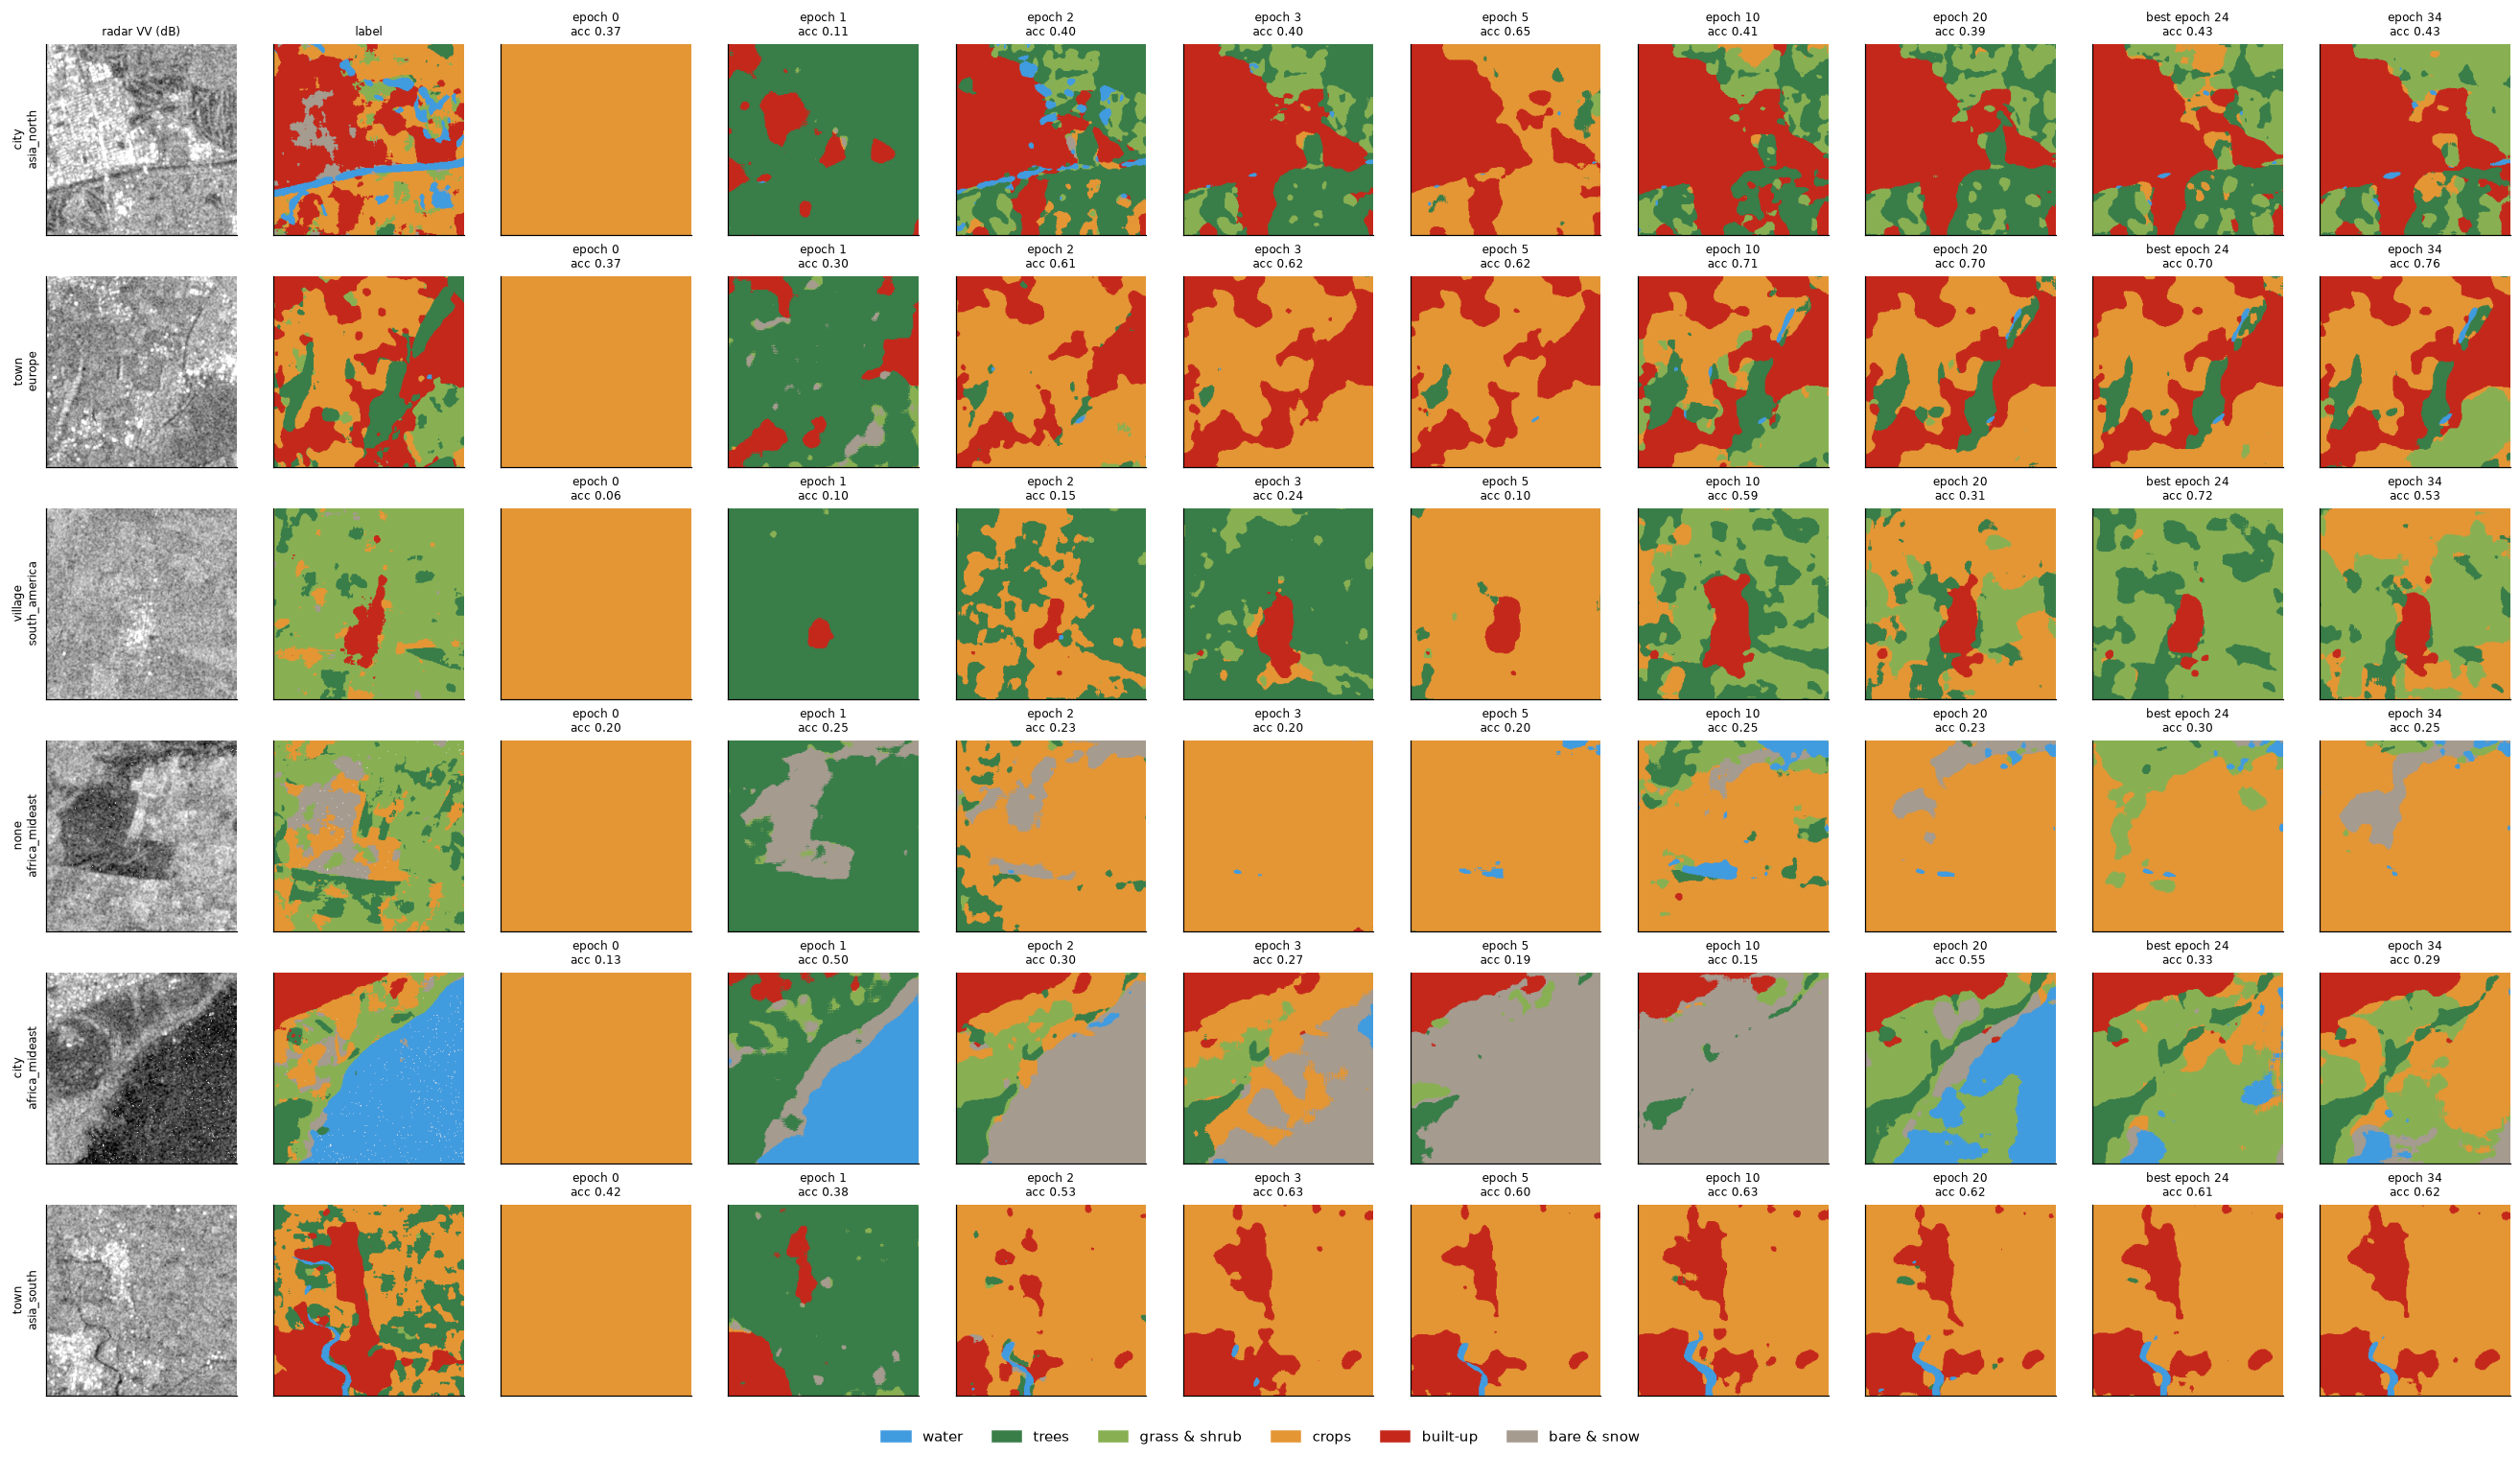

In [12]:
if WATCH:
    show_eps = [e for e in dict.fromkeys([0, 1, 2, 3, 5, 10, 20, best_ep, eps[-1]]) if e in snap]
    n = len(lab)
    fig, axes = plt.subplots(n, len(show_eps) + 2, figsize=(2.2 * (len(show_eps) + 2), 2.3 * n), squeeze=False)
    for i in range(n):
        vv = ex["s1"][i, 0].astype(float) / 100; vv[ex["s1"][i, 0] == -32768] = np.nan
        axes[i, 0].imshow(vv, cmap="gray", vmin=-25, vmax=0); axes[i, 1].imshow(colourise(lab[i]))
        axes[i, 0].set_ylabel(f"{ex['settlement'][i]}\n{ex['region'][i]}", fontsize=8)
        for j, e in enumerate(show_eps):
            pr = snap[e]["pred"][i].astype(int); ok = lab[i] >= 0
            axes[i, j + 2].imshow(colourise(np.where(lab[i] >= -1, pr, -1)))
            axes[i, j + 2].set_title(f"{'best ' if e == best_ep else ''}epoch {e}\nacc {(pr[ok] == lab[i][ok]).mean():.2f}", fontsize=8)
    axes[0, 0].set_title("radar VV (dB)", fontsize=8); axes[0, 1].set_title("label", fontsize=8)
    for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLOURS]
    fig.legend(handles, DISPLAY_NAMES, loc="lower center", ncol=6, frameon=False)
    plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

### How much the maps still change from one epoch to the next

Left: pixel accuracy on the 6 scenes per epoch. Right: share of pixels whose predicted class changed since the
previous epoch. Large at first (the network is still finding the classes), small at the end (the learning rate is
low and the maps only get refined): this is what convergence looks like in the output images.

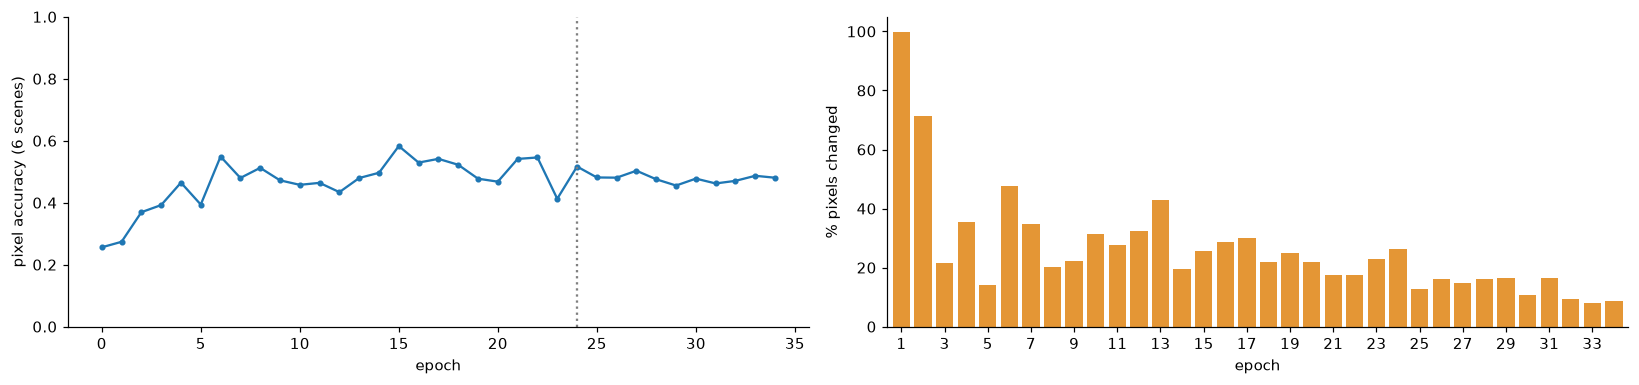

epoch 0 -> 1: 100% of pixels changed; last epoch: 8.6%


In [13]:
if WATCH:
    chg = pd.Series({e: (snap[e]["pred"] != snap[p]["pred"]).mean() for p, e in zip(eps[:-1], eps[1:])})
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
    acc.plot(ax=ax[0], marker="o", ms=3); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("pixel accuracy (6 scenes)")
    ax[0].axvline(best_ep, color="grey", ls=":"); ax[0].set_ylim(0, 1)
    (chg * 100).plot.bar(ax=ax[1], color="#e49635", width=0.8); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("% pixels changed")
    ax[1].set_xticks(range(0, len(chg), max(1, len(chg) // 15)), chg.index[::max(1, len(chg) // 15)], rotation=0)
    plt.tight_layout(); plt.show()
    print(f"epoch 0 -> 1: {chg.iloc[0] * 100:.0f}% of pixels changed; last epoch: {chg.iloc[-1] * 100:.1f}%")

### Confidence and built-up probability while learning

For the first (city) scene: the network's confidence (highest class probability; dark = unsure) and its built-up
probability after the same epochs. Early on everything is uncertain; later the network is confident inside
homogeneous areas and unsure along class borders, which is where most errors are.

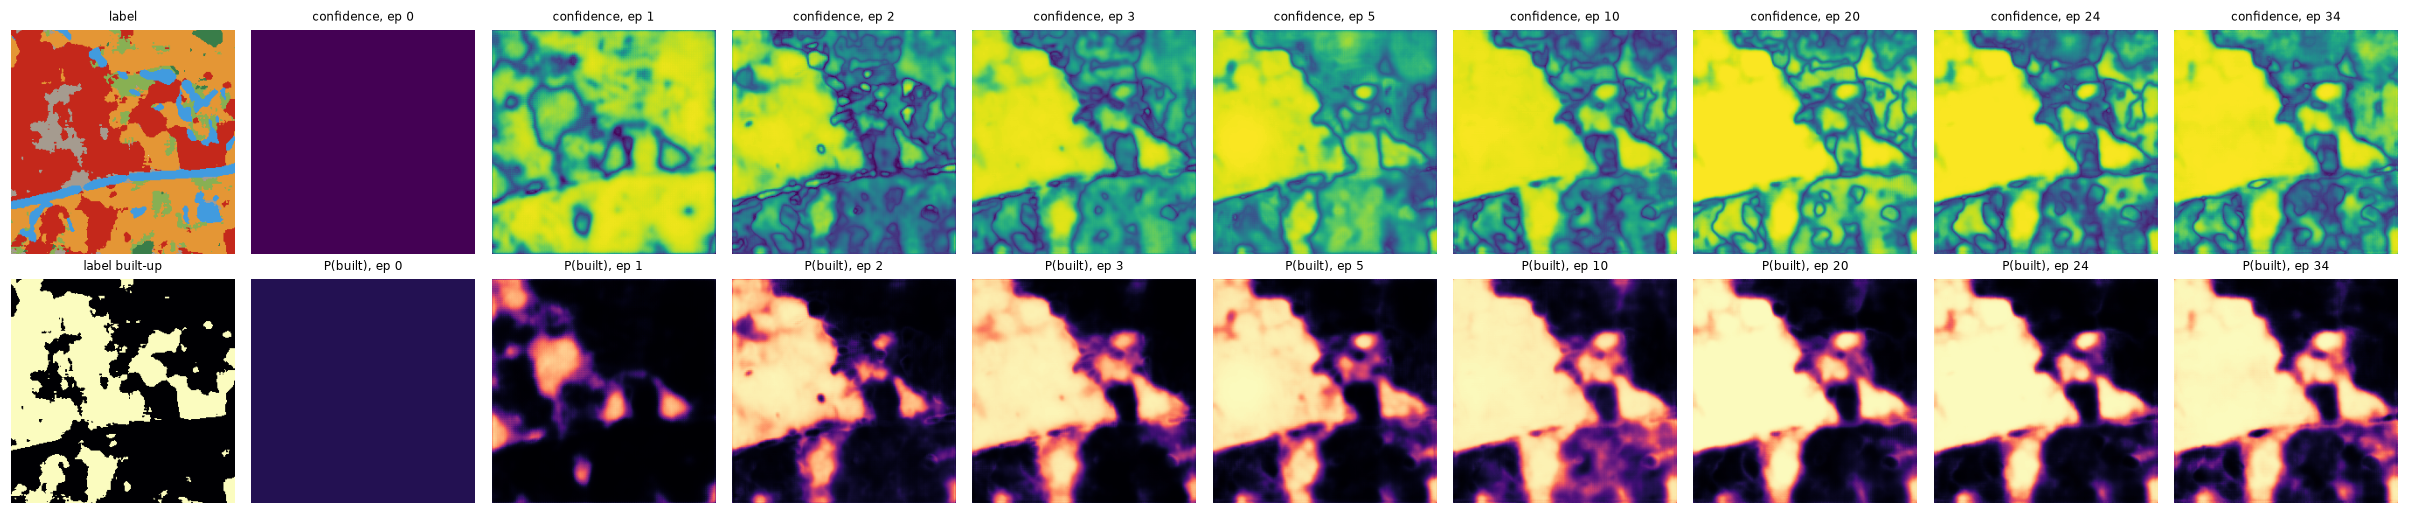

In [14]:
if WATCH:
    i = 0
    fig, axes = plt.subplots(2, len(show_eps) + 1, figsize=(2.2 * (len(show_eps) + 1), 4.8), squeeze=False)
    axes[0, 0].imshow(colourise(lab[i])); axes[0, 0].set_title("label", fontsize=8)
    axes[1, 0].imshow(lab[i] == BUILT, cmap="magma", vmin=0, vmax=1); axes[1, 0].set_title("label built-up", fontsize=8)
    for j, e in enumerate(show_eps):
        axes[0, j + 1].imshow(snap[e]["conf"][i] / 255, cmap="viridis", vmin=0.2, vmax=1)
        axes[1, j + 1].imshow(snap[e]["p_built"][i] / 255, cmap="magma", vmin=0, vmax=1)
        axes[0, j + 1].set_title(f"confidence, ep {e}", fontsize=8); axes[1, j + 1].set_title(f"P(built), ep {e}", fontsize=8)
    for a in axes.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()

### Animation: all 6 scenes through every epoch

Top row: labels; bottom row: the prediction after the epoch shown in the corner (one frame per epoch).


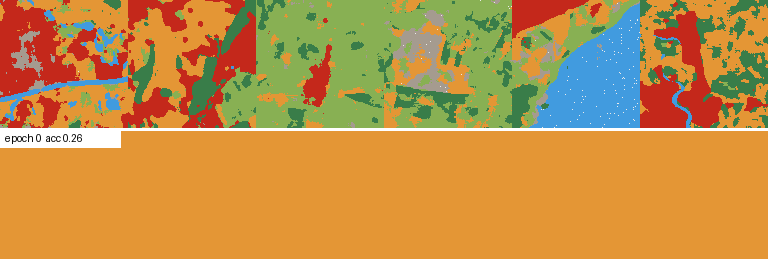

saved /home/jovyan/vault/s1-lulc/train/runs/E3v/snapshots/learning.gif


In [15]:
if WATCH:
    from PIL import Image as PILImage, ImageDraw
    top = np.concatenate([colourise(l) for l in lab], axis=1)
    frames = []
    for e in eps:
        bot = np.concatenate([colourise(p.astype(int)) for p in snap[e]["pred"]], axis=1)
        im = PILImage.fromarray(np.concatenate([top, np.full((6, top.shape[1], 3), 255, np.uint8), bot]))
        im = im.resize((im.width // 2, im.height // 2), PILImage.NEAREST)
        d = ImageDraw.Draw(im); d.rectangle([0, im.height // 2, 120, im.height // 2 + 18], fill=(255, 255, 255))
        d.text((5, im.height // 2 + 3), f"epoch {e}  acc {acc[e]:.2f}", fill=(0, 0, 0))
        frames.append(im)
    buf = io.BytesIO()
    frames[0].save(buf, format="GIF", save_all=True, append_images=frames[1:], duration=[1200] + [450] * (len(frames) - 2) + [2500], loop=0)
    (W / "snapshots" / "learning.gif").write_bytes(buf.getvalue())
    display(HTML(f'<img src="data:image/gif;base64,{base64.b64encode(buf.getvalue()).decode()}" style="max-width:100%">'))
    print(f"saved {W / 'snapshots' / 'learning.gif'}")